# Bài toán 3 — Chuẩn bị dữ liệu dự báo

## 1. Xác định bài toán

Dự báo **Revenue** (doanh thu theo định nghĩa nguồn) và **COGS** (giá vốn hàng bán) cho 548 ngày liên tiếp. Đánh giá riêng hai chỉ tiêu bằng MAE, RMSE và R².

**Câu hỏi nghiên cứu.** Trên cùng các giai đoạn kiểm tra theo thời gian, phương pháp nào dự báo sát nhất? Mô hình mùa vụ mức gốc cố định và hiệu ứng thứ có hạn chế gì? Việc phân rã doanh thu theo số dòng hàng, giá trị mỗi dòng, xu hướng kinh doanh và phân khúc sản phẩm có giúp cải thiện dự báo dài hạn không?

**Phạm vi thực nghiệm.** Phát triển mô hình từ 04/07/2012 đến hết 01/07/2021; đánh giá 548 ngày từ 02/07/2021 đến 31/12/2022. Không dùng nhãn của kỳ đánh giá để khám phá, lựa chọn tham số hoặc khớp mô hình trong quy trình này. Kiến trúc đã từng được khảo sát hồi cứu trên lịch sử rộng hơn, nên kỳ đánh giá không phải một holdout độc lập đối với quá trình hình thành kiến trúc.

## 2. Thu thập và hiểu dữ liệu

Nguồn chính là `data/raw/sales.csv` trong Datathon 2026 Round 1, gồm 3.833 ngày và ba cột `Date`, `Revenue`, `COGS`. Khóa theo dòng là `Date`. Đơn vị tiền tệ được giữ theo nguồn. Bổ sung `orders.csv` (ngày đơn hàng), `order_items.csv` (dòng hàng, số lượng, đơn giá), `products.csv` (giá tham chiếu, giá vốn, phân khúc). Chỉ đọc các cột cần thiết. Không thay đổi dữ liệu gốc.

**Thứ tự chạy.** `01_du_lieu.ipynb` → `02_mo_hinh.ipynb` → `03_danh_gia.ipynb` → `04_do_nhay.ipynb` → `05_bao_cao.ipynb`. Notebook này khảo sát và định nghĩa dữ liệu đầu vào; không xuất file trung gian, không huấn luyện mô hình. Notebook 02 sẽ xây dựng lại dữ liệu cho từng mốc train.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sales_path = Path("data/raw/sales.csv")
start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
project_root = next(
    (folder for folder in (start, *start.parents) if (folder / sales_path).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Không tìm thấy data/raw/sales.csv. Hãy đặt notebook trong dự án "
        "hoặc trỏ RETAIL_ANALYTICS_ROOT về thư mục gốc."
    )

targets = ["Revenue", "COGS"]
columns = ["Date", *targets]
sales_daily = pd.read_csv(project_root / sales_path, usecols=columns, dtype="string")[columns]
sales_daily["Date"] = pd.to_datetime(sales_daily["Date"], format="%Y-%m-%d", errors="raise")
if sales_daily["Date"].isna().any():
    raise ValueError("Date có giá trị thiếu.")

sales_daily[targets] = sales_daily[targets].apply(pd.to_numeric, errors="raise").astype("float64")
sales_daily = sales_daily.sort_values("Date", ignore_index=True)

history_start = pd.Timestamp("2012-07-04")
history_end = pd.Timestamp("2022-12-31")
expected_dates = pd.date_range(history_start, history_end, freq="D")
if not pd.DatetimeIndex(sales_daily["Date"]).equals(expected_dates):
    raise ValueError("Lịch sử có ngày thiếu, trùng hoặc ngoài khoảng đã xác nhận.")
if not np.isfinite(sales_daily[targets].to_numpy(dtype=float)).all():
    raise ValueError("Revenue hoặc COGS có giá trị thiếu hoặc không hữu hạn.")


horizon = 548
n_folds = 3
dev_start = history_start
dev_end = pd.Timestamp("2021-07-01")
test_start = dev_end + pd.Timedelta(days=1)
test_dates = pd.date_range(test_start, history_end, freq="D")
assert len(test_dates) == horizon
assert sales_daily["Date"].iloc[-horizon - 1] == dev_end
sales_dev = sales_daily.set_index("Date").loc[dev_start:dev_end].copy()

print(f"Lịch sử: {history_start:%d/%m/%Y}–{history_end:%d/%m/%Y} | {len(sales_daily):,} ngày")
print("Lịch theo ngày liên tục, mỗi ngày một dòng và hai chỉ tiêu đều hữu hạn.")
print(f"Phát triển: {dev_start:%d/%m/%Y}–{dev_end:%d/%m/%Y} | {len(sales_dev):,} ngày")
print(f"Đánh giá: {test_start:%d/%m/%Y}–{history_end:%d/%m/%Y} | {len(test_dates):,} ngày (chỉ xác định phạm vi)")
assert sales_dev.index.max() == dev_end
assert len(sales_dev) + len(test_dates) == len(sales_daily)
display(sales_dev.head())

Lịch sử: 04/07/2012–31/12/2022 | 3,833 ngày
Lịch theo ngày liên tục, mỗi ngày một dòng và hai chỉ tiêu đều hữu hạn.
Phát triển: 04/07/2012–01/07/2021 | 3,285 ngày
Đánh giá: 02/07/2021–31/12/2022 | 548 ngày (chỉ xác định phạm vi)


/tmp/ipykernel_10296/3629941925.py:44: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  test_start = dev_end + pd.Timedelta(days=1)


,Revenue,COGS
Date,,
2012-07-04,5123547.94,3982991.19
2012-07-05,2751773.45,2150580.23
2012-07-06,3054029.42,2517632.84
2012-07-07,2667930.94,2108246.62
2012-07-08,2360851.90,1808622.79


## 3. Khám phá dữ liệu

Thống kê và biểu đồ dưới đây dùng dữ liệu phát triển đến 01/07/2021. Trung bình trượt 28 ngày dùng để quan sát xu hướng trong lịch sử. Bảng năm dùng các năm đủ dữ liệu từ 2013 đến 2020.

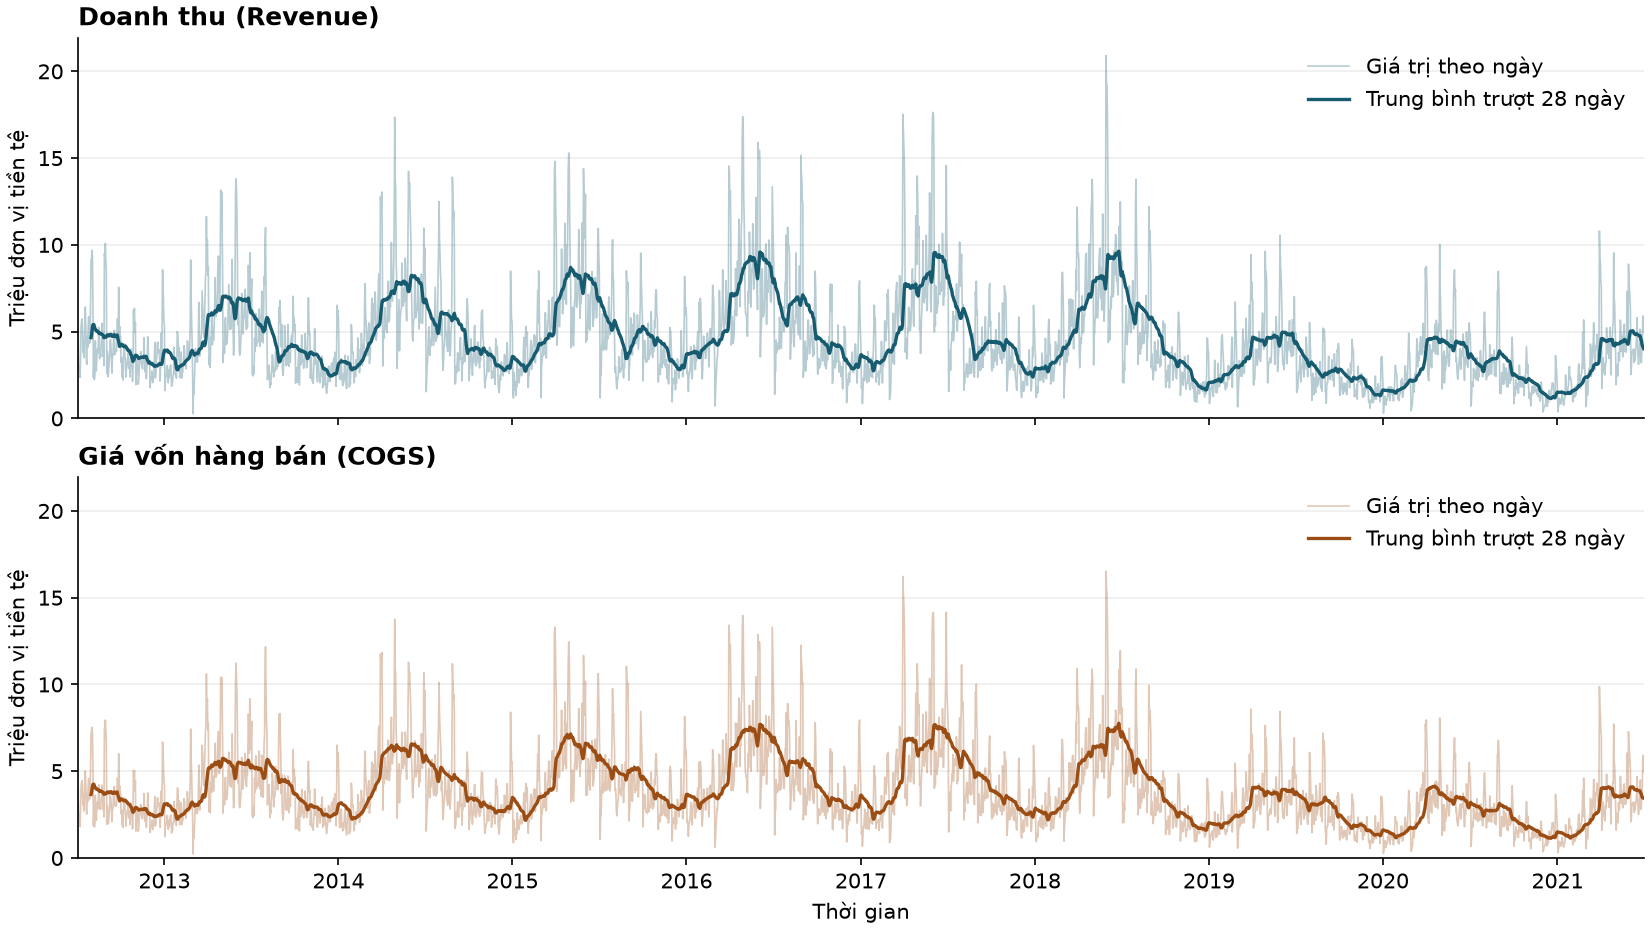

In [2]:
from io import BytesIO

from IPython.display import Image
from matplotlib.ticker import MaxNLocator

rolling_days = 28
to_millions = 1_000_000
rolling_mean = sales_dev.rolling(rolling_days).mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, sharey=True, layout="constrained")
series_styles = [
    ("Revenue", "Doanh thu (Revenue)", "#175B70"),
    ("COGS", "Giá vốn hàng bán (COGS)", "#9C4D14"),
]
for ax, (column, title, color) in zip(axes, series_styles):
    ax.plot(
        sales_dev.index, sales_dev[column] / to_millions,
        color=color, alpha=0.31, linewidth=0.8, label="Giá trị theo ngày",
    )
    ax.plot(
        rolling_mean.index, rolling_mean[column] / to_millions,
        color=color, linewidth=1.6, label="Trung bình trượt 28 ngày",
    )
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylabel("Triệu đơn vị tiền tệ")
    ax.set_ylim(bottom=0)
    ax.set_xlim(dev_start, dev_end)
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper right", frameon=False)

axes[-1].set_xlabel("Thời gian")
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=150)
    display(Image(data=buffer.getvalue(), width=950))
plt.close(fig)

In [3]:
full_years = sales_dev.loc["2013":"2020"]
annual_daily_mean = full_years.groupby(full_years.index.year)[targets].mean()
annual_daily_mean.index.name = "Năm"
annual_daily_mean_millions = (annual_daily_mean / to_millions).rename(
    columns={"Revenue": "Revenue (triệu/ngày)", "COGS": "COGS (triệu/ngày)"}
)
display(annual_daily_mean_millions.round(2))

change_2019 = (annual_daily_mean.loc[2019] / annual_daily_mean.loc[2018] - 1) * 100
for column, percent in change_2019.items():
    print(f"{column}: thay đổi trung bình ngày năm 2019 so với 2018 là {percent:+.1f}%.")

,Revenue (triệu/ngày),COGS (triệu/ngày)
Năm,,
2013,4.54,4.02
2014,5.13,4.31
2015,5.18,4.56
2016,5.75,4.86
2017,5.24,4.64
2018,5.07,4.23
2019,3.11,2.75
2020,2.88,2.42


Revenue: thay đổi trung bình ngày năm 2019 so với 2018 là -38.6%.
COGS: thay đổi trung bình ngày năm 2019 so với 2018 là -34.8%.


**Nhận xét.** Trung bình ngày của hai chỉ tiêu tăng trong những năm đầu, sau đó giảm mạnh vào năm 2019. Revenue giảm 38,6% và COGS giảm 34,8% so với 2018 (làm tròn một chữ số). Đây là bằng chứng về sự thay đổi mức kinh doanh, không phải bằng chứng về một nguyên nhân kinh tế cụ thể. Cần kiểm tra mô hình mức gốc cố định và mô hình thích nghi xu hướng bằng validation.

## 4. Tiền xử lý và tạo đặc trưng

Giữ nguyên kiểm tra ngày, kiểu số và giá trị hữu hạn ở trên. Không tự điền, cắt ngọn hay loại bỏ các đỉnh hợp lệ. Đặc trưng lịch có thể biết trước gồm tháng, ngày, thứ, số ngày đến cuối tháng, năm chẵn/lẻ. Các hệ số mùa vụ, xu hướng, trung bình trượt và hiệu chỉnh sai số chỉ được học từ lịch sử sẵn có ở mỗi mốc train.

### 4.1. Khai thác mùa vụ theo tháng–ngày và hiệu ứng thứ

Chuẩn hóa từng năm đầy đủ theo trung bình ngày của chính năm đó để giảm ảnh hưởng của khác biệt mức kinh doanh. Khảo sát mẫu theo vị trí trong tháng và thứ trong tuần; đây là cơ sở kiểm tra các mô hình mùa vụ hiện có, không phải hệ số đã huấn luyện dùng chung cho mọi fold.

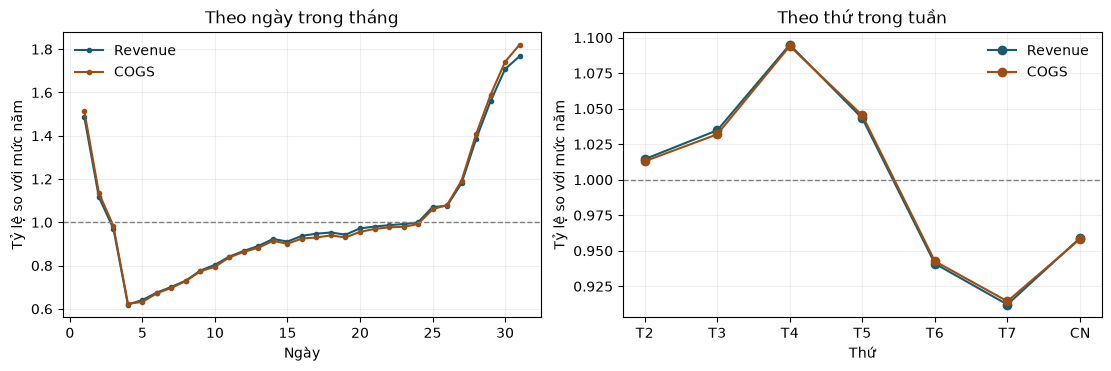

,Ngày thấp nhất,Ngày cao nhất,Biên độ theo ngày,Biên độ theo thứ
Revenue,4,31,1.147,0.183
COGS,4,31,1.197,0.180


In [4]:
normalized = full_years[targets].div(full_years.groupby(full_years.index.year)[targets].transform("mean"))
dom_pattern = normalized.groupby(normalized.index.day).mean()
weekday_pattern = normalized.groupby(normalized.index.dayofweek).mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
for col, _, color in series_styles:
    axes[0].plot(dom_pattern.index, dom_pattern[col], label=col, color=color, marker=".")
    axes[1].plot(weekday_pattern.index, weekday_pattern[col], label=col, color=color, marker="o")
for ax, title, xlabel in zip(axes, ["Theo ngày trong tháng", "Theo thứ trong tuần"], ["Ngày", "Thứ"]):
    ax.axhline(1, color="gray", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel=xlabel, ylabel="Tỷ lệ so với mức năm")
    ax.grid(alpha=.2); ax.legend(frameon=False)
axes[1].set_xticks(range(7), ["T2", "T3", "T4", "T5", "T6", "T7", "CN"])
plt.show()
display(pd.DataFrame({"Ngày thấp nhất":dom_pattern.idxmin(), "Ngày cao nhất":dom_pattern.idxmax(),
                      "Biên độ theo ngày":dom_pattern.max()-dom_pattern.min(),
                      "Biên độ theo thứ":weekday_pattern.max()-weekday_pattern.min()}).round(3))

### 4.2. Dữ liệu giao dịch phục vụ phân rã Revenue và COGS

Giữ phạm vi toàn bộ trạng thái đơn hàng để khớp đúng định nghĩa `sales.csv` (không áp dụng phạm vi delivered-only của bài phân cụm). Theo nguồn, Revenue đối soát bằng `quantity × unit_price`, COGS bằng `quantity × cogs`; không trừ `discount_amount` thêm lần nữa. Dùng khóa nhiều–một ở hai phép nối, không loại các dòng hàng trùng nội dung vì chúng có thể là giao dịch hợp lệ.

Ký hiệu $N_t$ là số dòng hàng, $r_t$ và $c_t$ là Revenue và COGS trung bình trên mỗi dòng. Khi đó $Revenue_t=N_t r_t$, $COGS_t=N_t c_t$. Ngoài ra lưu giá tham chiếu, giá bán và số lượng trung bình để khảo sát các thành phần chi tiết hơn. Chỉ sử dụng cột thuộc dữ liệu lịch sử; giả định giá và giá vốn trong danh mục sản phẩm là thuộc tính tham chiếu theo nguồn, không có lịch sử phiên bản để xác minh giá trị tại từng thời điểm.

In [5]:
def load_factor_data(root, cutoff, sales_history):
    """Chỉ tạo đặc trưng giao dịch đến hết cutoff; sales_history là nhãn theo ngày."""
    cutoff = pd.Timestamp(cutoff)
    raw = Path(root) / "data" / "raw"
    orders = pd.read_csv(raw / "orders.csv", usecols=["order_id", "order_date"])
    orders["order_date"] = pd.to_datetime(orders["order_date"], format="%Y-%m-%d", errors="raise")
    items = pd.read_csv(raw / "order_items.csv", usecols=["order_id", "product_id", "quantity", "unit_price"])
    products = pd.read_csv(raw / "products.csv", usecols=["product_id", "segment", "price", "cogs"])
    assert orders.order_id.notna().all() and orders.order_id.is_unique and orders.order_date.notna().all()
    assert products.product_id.notna().all() and products.product_id.is_unique
    assert items.order_id.notna().all() and items.order_id.isin(orders.order_id).all()
    # Cắt đơn hàng trước khi tính doanh thu, giá vốn hoặc thống kê giao dịch.
    orders = orders.loc[orders.order_date <= cutoff]
    lines = items.merge(orders, on="order_id", how="inner", validate="many_to_one")
    expected = int(items.order_id.isin(orders.order_id).sum())
    assert len(lines) == expected
    del items, orders
    assert lines.product_id.notna().all() and lines.product_id.isin(products.product_id).all()
    lines = lines.merge(products, on="product_id", how="left", validate="many_to_one")
    assert len(lines) == expected and lines.order_date.max() <= cutoff
    assert lines.segment.notna().all()
    numeric = ["quantity", "unit_price", "price", "cogs"]
    assert np.isfinite(lines[numeric].to_numpy(dtype=float)).all()
    assert (lines[numeric] > 0).all().all(), "Kiểm tra giá trị không dương trước khi dùng log/tỷ lệ."
    lines["line_revenue"] = lines.quantity * lines.unit_price
    lines["line_cost"] = lines.quantity * lines.cogs
    daily = lines.groupby("order_date").agg(
        lines=("quantity", "size"), quantity=("quantity", "mean"),
        price=("price", "mean"), cost=("cogs", "mean"), actual_price=("unit_price", "mean"),
        Revenue=("line_revenue", "sum"), COGS=("line_cost", "sum"))
    daily["price_factor"] = daily.actual_price / daily.price
    source = sales_history.loc[:cutoff, ["Revenue", "COGS"]]
    assert daily.index.equals(source.index.rename("order_date"))
    errors = (daily[targets] - source[targets]).abs().max()
    # Đối soát theo ngày: nguồn sales làm tròn đến 2 chữ số, dùng sai số tuyệt đối nhỏ.
    assert np.allclose(daily[targets], source[targets], atol=.011, rtol=0), errors
    daily[targets] = source[targets].to_numpy()
    daily["revenue_per_line"] = daily.Revenue / daily.lines
    daily["cogs_per_line"] = daily.COGS / daily.lines
    lines["N"] = 1
    lines = lines.rename(columns={"price":"base", "unit_price":"actual", "cogs":"cost",
                                  "line_revenue":"revenue", "line_cost":"line_cogs"})
    panel = (lines.groupby(["order_date", "segment"])[["base", "actual", "cost", "N", "quantity", "revenue", "line_cogs"]]
             .sum().unstack(fill_value=0).sort_index())
    assert panel.index.equals(daily.index)
    assert (panel["N"].sum(axis=1) == daily.lines).all()
    assert np.allclose(panel["revenue"].sum(axis=1), daily.Revenue, atol=.011, rtol=0)
    assert np.allclose(panel["line_cogs"].sum(axis=1), daily.COGS, atol=.011, rtol=0)
    return daily, panel, errors

factor_daily, segment_daily, reconciliation = load_factor_data(project_root, dev_end, sales_dev)
print(f"Đã đối soát {len(factor_daily):,} ngày, {factor_daily.lines.sum():,} dòng hàng, {segment_daily['N'].shape[1]} phân khúc.")
display(reconciliation.rename("Sai lệch tuyệt đối lớn nhất theo ngày").to_frame())
display(factor_daily.head())

Đã đối soát 3,285 ngày, 661,176 dòng hàng, 8 phân khúc.


,Sai lệch tuyệt đối lớn nhất theo ngày
Revenue,1.862645e-09
COGS,4.999269e-03


,lines,quantity,price,cost,actual_price,Revenue,COGS,price_factor,revenue_per_line,cogs_per_line
order_date,,,,,,,,,,
2012-07-04,174,4.465517,6407.267604,4884.986815,6394.123563,5123547.94,3982991.19,0.997949,29445.677816,22890.753966
2012-07-05,103,4.155340,6794.188475,5284.636956,6744.283107,2751773.45,2150580.23,0.992655,26716.247087,20879.419709
2012-07-06,99,4.454545,6785.285004,5446.615257,6793.819596,3054029.42,2517632.84,1.001258,30848.782020,25430.634747
2012-07-07,75,4.853333,7464.997191,5780.123349,7475.478533,2667930.94,2108246.62,1.001404,35572.412533,28109.954933
2012-07-08,94,4.191489,5757.646716,4462.581049,5766.682021,2360851.90,1808622.79,1.001569,25115.445745,19240.667979


### 4.3. Tách biến động số dòng hàng và giá trị trên mỗi dòng

So sánh các năm đầy đủ trong phạm vi phát triển. Giá trị mỗi dòng theo năm được tính bằng tổng tiền chia tổng số dòng (trung bình có trọng số theo số dòng). Sự khác biệt giữa các xu hướng là động cơ để thử mô hình dự báo thành phần, không mặc định rằng phân rã sẽ luôn có sai số thấp hơn.

,lines_per_day,revenue_per_line,cogs_per_line,price_factor
order_date,,,,
2013,239.290,18973.557,16784.558,0.908
2014,249.551,20550.314,17287.041,0.947
2015,253.526,20423.548,17997.577,0.908
2016,248.347,23154.636,19589.190,0.947
2017,229.290,22835.960,20245.735,0.906
2018,205.841,24624.959,20526.217,0.946
2019,123.082,25304.428,22375.134,0.907
2020,101.743,28318.174,23795.185,0.947


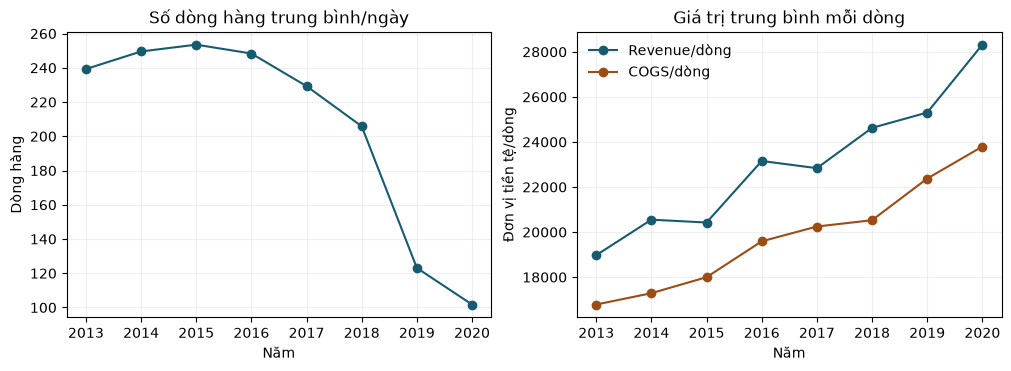

Thay đổi 2019 so với 2018 (%):


lines_per_day      -40.21
revenue_per_line     2.76
cogs_per_line        9.01
dtype: float64

In [6]:
factor_full = factor_daily.loc["2013":"2020"]
annual_factor = factor_full.groupby(factor_full.index.year).agg(
    lines_per_day=("lines", "mean"), total_lines=("lines", "sum"),
    Revenue=("Revenue", "sum"), COGS=("COGS", "sum"), price_factor=("price_factor", "mean"))
annual_factor["revenue_per_line"] = annual_factor.Revenue / annual_factor.total_lines
annual_factor["cogs_per_line"] = annual_factor.COGS / annual_factor.total_lines
display(annual_factor[["lines_per_day", "revenue_per_line", "cogs_per_line", "price_factor"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].plot(annual_factor.index, annual_factor.lines_per_day, marker="o", color="#175B70")
axes[0].set(title="Số dòng hàng trung bình/ngày", ylabel="Dòng hàng")
for col, label, color in [("revenue_per_line", "Revenue/dòng", "#175B70"), ("cogs_per_line", "COGS/dòng", "#9C4D14")]:
    axes[1].plot(annual_factor.index, annual_factor[col], marker="o", label=label, color=color)
axes[1].set(title="Giá trị trung bình mỗi dòng", ylabel="Đơn vị tiền tệ/dòng")
axes[1].legend(frameon=False)
for ax in axes: ax.grid(alpha=.2); ax.set_xlabel("Năm")
plt.show()
print("Thay đổi 2019 so với 2018 (%):")
display(((annual_factor.loc[2019] / annual_factor.loc[2018] - 1) * 100)[["lines_per_day", "revenue_per_line", "cogs_per_line"]].round(2))

### 4.4. Chu kỳ năm chẵn/lẻ và khác biệt giữa các phân khúc

Tỷ lệ giá bán/giá tham chiếu là tỷ lệ giữa trung bình đơn giá bán và trung bình giá tham chiếu theo ngày (không phải tỷ lệ giảm giá trên hóa đơn). Khảo sát tính chẵn/lẻ theo các năm đầy đủ. Tiếp theo so sánh cơ cấu số dòng hàng và doanh thu của từng phân khúc để xem liệu mô hình tổng hợp có bỏ qua sự khác biệt về cơ cấu hay không.

,Tỷ lệ giá bán/giá tham chiếu (%)
order_date,
Năm chẵn,94.69
Năm lẻ,90.74


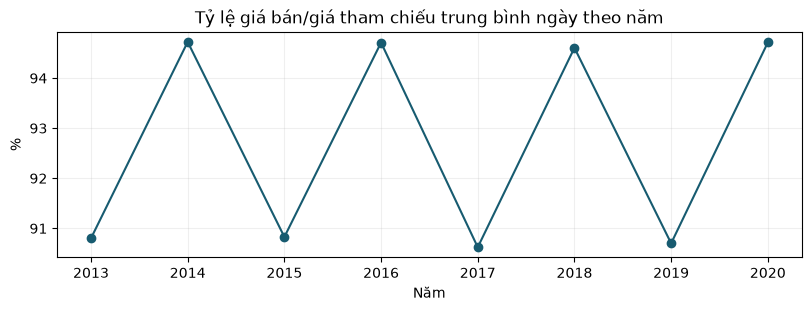

,Số dòng hàng,Revenue,COGS,Tỷ trọng số dòng (%),Tỷ trọng Revenue (%),Revenue/dòng,COGS/dòng
segment,,,,,,,
Activewear,219791,1.933075e+09,1.589964e+09,33.24,13.01,8795.06,7233.98
All-weather,19555,3.612266e+08,3.230426e+08,2.96,2.43,18472.34,16519.69
Balanced,89177,4.357204e+09,3.746398e+09,13.49,29.33,48860.18,42010.81
Everyday,171705,5.034891e+09,4.314180e+09,25.97,33.89,29322.91,25125.53
Performance,89788,2.219314e+09,1.956533e+09,13.58,14.94,24717.27,21790.59
Premium,28574,4.371858e+08,3.875509e+08,4.32,2.94,15300.13,13563.06
Standard,9769,2.094846e+08,1.725928e+08,1.48,1.41,21443.81,17667.39
Trendy,32817,3.024646e+08,2.446814e+08,4.96,2.04,9216.70,7455.93


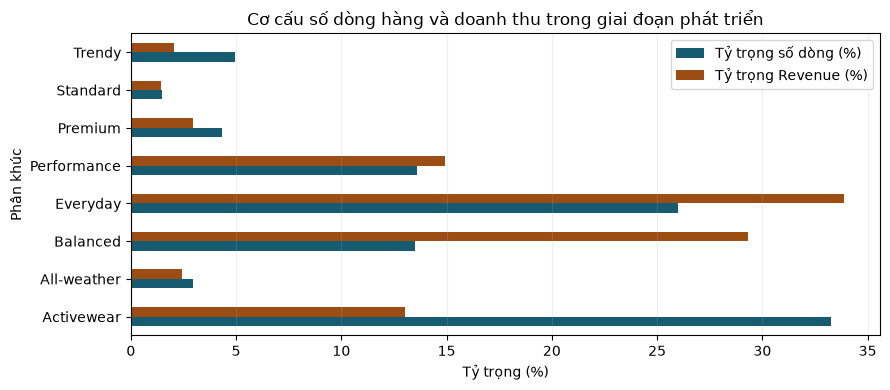

In [7]:
parity_summary = annual_factor.groupby(annual_factor.index % 2)["price_factor"].mean().rename(index={0:"Năm chẵn",1:"Năm lẻ"})
display((100*parity_summary).rename("Tỷ lệ giá bán/giá tham chiếu (%)").to_frame().round(2))
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
ax.plot(annual_factor.index, annual_factor.price_factor*100, color="#175B70", marker="o")
ax.set(xlabel="Năm", ylabel="%", title="Tỷ lệ giá bán/giá tham chiếu trung bình ngày theo năm")
ax.set_xticks(annual_factor.index); ax.grid(alpha=.2); plt.show()
segment_summary = pd.DataFrame({"Số dòng hàng":segment_daily["N"].sum(),
                                "Revenue":segment_daily["revenue"].sum(),
                                "COGS":segment_daily["line_cogs"].sum()})
segment_summary["Tỷ trọng số dòng (%)"] = segment_summary["Số dòng hàng"] / segment_summary["Số dòng hàng"].sum() * 100
segment_summary["Tỷ trọng Revenue (%)"] = segment_summary.Revenue / segment_summary.Revenue.sum() * 100
segment_summary["Revenue/dòng"] = segment_summary.Revenue / segment_summary["Số dòng hàng"]
segment_summary["COGS/dòng"] = segment_summary.COGS / segment_summary["Số dòng hàng"]
display(segment_summary.round(2))
ax = segment_summary[["Tỷ trọng số dòng (%)", "Tỷ trọng Revenue (%)"]].plot.barh(figsize=(9, 4), color=["#175B70", "#9C4D14"])
ax.set(xlabel="Tỷ trọng (%)", ylabel="Phân khúc", title="Cơ cấu số dòng hàng và doanh thu trong giai đoạn phát triển")
ax.grid(axis="x", alpha=.2); plt.tight_layout(); plt.show()

### 4.5. Tổng hợp theo tháng đã kết thúc và giới hạn tại từng mốc dự báo

Các mô hình học mức tháng cần loại tháng không đầy đủ ở hai đầu của lịch sử. Với mốc cuối 01/07/2021, tháng 07/2021 chỉ có một ngày quan sát; giữ ngày đó cho mô hình ngày, nhưng không coi là một tháng đầy đủ. Luôn cắt bảng ngày trước khi tổng hợp tháng. Quy tắc này cũng áp dụng cho từng fold validation, không được lấy tổng tháng đã tính từ dữ liệu sau mốc train.

In [8]:
def complete_month_factors(daily, segment_panel, cutoff):
    cutoff = pd.Timestamp(cutoff)
    h = daily.loc[:cutoff]
    s = segment_panel.loc[:cutoff]
    assert h.index.equals(s.index) and h.index.max() <= cutoff
    counts = h.resample("MS").size()
    complete = counts.index[counts.eq(counts.index.days_in_month)]
    monthly = h[["lines", "Revenue", "COGS"]].resample("MS").sum().loc[complete]
    seg = (s[["N", "revenue", "line_cogs"]].resample("MS").sum().loc[complete]
           .rename(columns={"N":"lines", "revenue":"Revenue", "line_cogs":"COGS"}, level=0))
    assert ((complete + pd.offsets.MonthEnd(0)) <= cutoff).all()
    assert (seg["lines"].sum(axis=1) == monthly.lines).all()
    assert np.allclose(seg["Revenue"].sum(axis=1), monthly.Revenue, atol=.011*31, rtol=0)
    assert np.allclose(seg["COGS"].sum(axis=1), monthly.COGS, atol=.011*31, rtol=0)
    return monthly, seg

monthly_factors, monthly_segments = complete_month_factors(factor_daily, segment_daily, dev_end)
print(f"Tháng đầy đủ: {len(monthly_factors)} | {monthly_factors.index.min():%m/%Y}–{monthly_factors.index.max():%m/%Y}")
assert monthly_factors.index.max() == pd.Timestamp("2021-06-01")
# Dùng chính quy tắc chia validation của notebook 02 để kiểm tra cắt thời gian.
fold_checks = []
for fold in range(1, n_folds+1):
    val_end = dev_end - pd.Timedelta(days=(n_folds-fold)*horizon)
    val_start = val_end - pd.Timedelta(days=horizon-1)
    train_end = val_start - pd.Timedelta(days=1)
    m, s = complete_month_factors(factor_daily, segment_daily, train_end)
    fold_checks.append({"Fold":fold,"Train đến":train_end.date(),"Validation từ":val_start.date(),
                        "Validation đến":val_end.date(),"Tháng đầy đủ cuối":m.index[-1].strftime("%m/%Y"),
                        "Số ngày validation":horizon})
display(pd.DataFrame(fold_checks))

Tháng đầy đủ: 107 | 08/2012–06/2021


/tmp/ipykernel_10296/192218174.py:23: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  val_end = dev_end - pd.Timedelta(days=(n_folds-fold)*horizon)
/tmp/ipykernel_10296/192218174.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  val_start = val_end - pd.Timedelta(days=horizon-1)
/tmp/ipykernel_10296/192218174.py:25: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  train_end = val_start - pd.Timedelta(days=1)
/tmp/ipykernel_10296/192218174.py:23: DeprecationWarning: The 'generic' unit for

,Fold,Train đến,Validation từ,Validation đến,Tháng đầy đủ cuối,Số ngày validation
0,1,2016-12-30,2016-12-31,2018-07-01,11/2016,548
1,2,2018-07-01,2018-07-02,2019-12-31,06/2018,548
2,3,2019-12-31,2020-01-01,2021-07-01,12/2019,548


## Kết luận khảo sát và định hướng xây dựng mô hình

**Kết quả định lượng trên giai đoạn phát triển:**

| Phát hiện | Kết quả | Ý nghĩa đối với mô hình |
|---|---|---|
| Mẫu theo ngày trong tháng | Trung bình chuẩn hóa thấp nhất vào ngày 4, cao nhất vào ngày 31 ở cả hai chỉ tiêu | Giữ mùa vụ lịch và thử học hình dạng ngày |
| Thay đổi mức 2019 so với 2018 | Revenue −38,6%; COGS −34,8% | Kiểm tra mô hình mức gốc cố định và mô hình thích nghi |
| Phân rã mức 2019 so với 2018 | Số dòng/ngày −40,21%; Revenue/dòng +2,76%; COGS/dòng +9,01% | Dự báo số dòng và giá trị mỗi dòng riêng |
| Tỷ lệ giá bán/giá tham chiếu | 94,69% ở năm chẵn; 90,74% ở năm lẻ (2013–2020) | Khai thác đặc trưng chẵn/lẻ |
| Khác biệt giữa phân khúc | Revenue/dòng của Activewear khoảng 8.795; Balanced khoảng 48.860 | Thử dự báo riêng từng phân khúc |

Các thống kê này chỉ mô tả dữ liệu quan sát, không suy diễn quan hệ nhân quả. Ngày 31 chỉ xuất hiện trong các tháng có 31 ngày; mẫu lịch còn chịu ảnh hưởng cơ cấu tháng.

- Mẫu theo ngày trong tháng và hiệu ứng thứ là cơ sở giữ các phương pháp mùa vụ hiện tại làm đối chứng. Tuy nhiên, mức gốc cố định không biểu diễn riêng sự thay đổi mức kinh doanh theo thời gian.
- Biến động số dòng hàng và giá trị mỗi dòng tạo cơ sở thử dự báo thành phần: mô hình đếm (Poisson), mô hình phi tuyến (HistGradient Boosting), hồi quy có điều chuẩn (Ridge) cho xu hướng và giá trị. Các thành phần chỉ được sử dụng nếu kiểm định theo thời gian hỗ trợ.
- Mẫu lịch và khác biệt chẵn/lẻ tạo cơ sở thử nhánh mùa vụ và học hình dạng ngày (CatBoost, đặc trưng chu kỳ Fourier).
- Khác biệt về cơ cấu và giá trị dòng hàng giữa các phân khúc tạo cơ sở thử nhánh phân khúc, kết hợp với dự báo tổng hợp; thay đổi mức kinh doanh tạo động cơ xem xét cơ chế phục hồi có điều kiện và hiệu chỉnh sai số ngoài mẫu.

Notebook 02 sẽ giữ các phương pháp đối chứng đã có, triển khai một mô hình Hybrid Ensemble kết hợp phân rã doanh thu và phân khúc sản phẩm, rồi so sánh trên cùng các cửa sổ validation. Notebook 04 sẽ kiểm tra đóng góp từng thành phần thay vì liệt kê các phiên bản thử nghiệm. Các nhận định trên là động cơ xây dựng mô hình, chưa phải kết quả chứng minh mô hình cải thiện.

**Giới hạn:** khảo sát chỉ dùng dữ liệu phát triển. Thông tin danh mục sản phẩm là dữ liệu tham chiếu tĩnh, không có phiên bản theo thời gian. Kỳ đánh giá cuối đã từng được sử dụng trong quá trình khảo sát kiến trúc hồi cứu; không khẳng định đây là một tập kiểm định độc lập hoàn toàn. Không dùng kỳ đánh giá cuối để lựa chọn tham số trong quy trình hiện tại.